# Predykcja cen nieruchomości

Wszystkie modele korzystają z jednego podziału czasowego rynku wtórnego. EDA pozostaje na końcu i analizuje wyłącznie wspólny trening. Celem jest cena ofertowa w PLN. Cena za m² nie jest cechą modelu; pola cenowe usuwamy również z `params`. Tytuły i opisy nadal wymagają kontroli pod kątem jawnej ceny.

## 1. Wczytanie danych

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

plik = pd.read_csv(Path('data/real_estate_ads.csv'))
display(plik.head())

,id,market,created_at_first,created_at,district_lon,district_lat,title,description,params,price,no_rooms,m,price_per_m,map_lon,map_lat
0,49341,secondary,2018-01-04 13:11:05,2018-01-08 11:27:35,16.9408,52.38356,NaN,<p>Zapraszam do zapoznania się z ofertą sprzed...,price<=>price<br>price<=>289000<br>price[curre...,289000.0,3,48.000000,6020.83,16.959516,52.391494
1,261720,secondary,2018-01-15 19:12:07,2018-01-25 11:11:31,16.9408,52.38356,NaN,<p>Zapraszam do zapoznania się z ofertą sprzed...,price<=>price<br>price<=>379000<br>price[curre...,379000.0,3,61.000000,6213.11,16.950743,52.380535
2,50441,secondary,2018-01-04 13:53:29,2018-01-11 05:55:12,16.9408,52.38356,Rataje Nowe Miasto Niski Blok,<p>Weychan Nieruchomości Monika Hałas - Kurcza...,price<=>price<br>price<=>339000<br>price[curre...,339000.0,3,63.000000,5380.95,16.945860,52.393188
3,203518,secondary,2018-01-12 11:10:57,2018-01-30 14:38:39,16.9408,52.38356,"Mieszkanie 3 pokojowe blisko tramwaju, Poznań os.",<p>Oferuję na sprzedaż jasne i zadbane mieszka...,price<=>price<br>price<=>330000<br>price[curre...,330000.0,3,59.200001,5574.32,16.980279,52.391129
4,5,secondary,2018-01-02 11:34:51,2018-01-18 14:22:29,16.9408,52.38356,"Inwestycja -rondo Rataje student AWF,POLITECHNIKA",<p><strong>Dwa pokoje na niskim piętrze tuż pr...,price<=>price<br>price<=>259000<br>price[curre...,259000.0,2,38.000000,6815.79,16.950027,52.395861


## 2. Jeden wspólny podział czasowy

Zostawiamy rynek wtórny oraz dodatnią, skończoną cenę i poprawną datę pierwszej publikacji. Dla powtórzonego ID zachowujemy najwcześniejszy dostępny zapis. Sortujemy po pierwszej publikacji i odkładamy ostatnie około 20% ofert; cały dzień graniczny trafia do testu. Braki cech nie powodują usuwania wierszy — uzupełniamy je w pipeline na podstawie treningu.

Podział po ID nie gwarantuje, że ta sama nieruchomość wystawiona pod różnymi ID nie pojawi się w obu częściach. Test służy do końcowego porównania, a nie do strojenia parametrów.

In [2]:
df = plik.loc[plik['market'].eq('secondary')].copy()
df['published_at'] = pd.to_datetime(df['created_at_first'], errors='coerce')
df['updated_at'] = pd.to_datetime(df['created_at'], errors='coerce')
df['price'] = pd.to_numeric(df['price'], errors='coerce')
valid_target = np.isfinite(df['price']) & df['price'].gt(0)
print('Wykluczone: brak daty lub poprawnej ceny:',
      int((~valid_target | df['published_at'].isna()).sum()))
df = (df.loc[valid_target & df['published_at'].notna()]
      .sort_values(['published_at', 'updated_at'], kind='stable')
      .drop_duplicates('id', keep='first').copy())
if len(df) < 2:
    raise ValueError('Za mało ofert do podziału.')
cutoff = df['published_at'].iloc[int(0.8 * len(df))].normalize()
train_idx = df.index[df['published_at'] < cutoff]
test_idx = df.index[df['published_at'] >= cutoff]
if not len(train_idx) or not len(test_idx):
    raise ValueError('Granica dzienna daje pusty trening lub test.')
assert set(train_idx).isdisjoint(test_idx)
assert set(df.loc[train_idx, 'id']).isdisjoint(df.loc[test_idx, 'id'])
assert df.loc[train_idx, 'published_at'].max() < df.loc[test_idx, 'published_at'].min()
print('Granica testu:', cutoff.date())
print('Trening:', len(train_idx), '| test:', len(test_idx))

Wykluczone: brak daty lub poprawnej ceny: 0
Granica testu: 2020-05-24
Trening: 4758 | test: 1196


## 3. Przygotowanie cech

Odległość haversine mierzy kilometry od punktu opisanego współrzędnymi `district_*`; nie zakładamy, że to centrum miasta. Niepoprawną powierzchnię traktujemy jako brak. Operacje są deterministyczne i nie uczą się statystyk z testu. `more` pozostaje kategorią liczby pokoi. Surowe `params` zachowujemy do audytu, a do modelu tworzymy osobne, oczyszczone pole.

In [3]:
df['m'] = pd.to_numeric(df['m'], errors='coerce')
df['m'] = df['m'].where(np.isfinite(df['m']) & df['m'].gt(0))
coords = df[['map_lat', 'map_lon', 'district_lat', 'district_lon']].apply(pd.to_numeric, errors='coerce')
coords_ok = (coords['map_lat'].between(-90, 90) & coords['district_lat'].between(-90, 90)
             & coords['map_lon'].between(-180, 180) & coords['district_lon'].between(-180, 180))
lat1, lon1, lat2, lon2 = [np.radians(coords[c]) for c in coords.columns]
a = np.sin((lat1-lat2)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon1-lon2)/2)**2
df['dist_from_c'] = (6371 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))).where(coords_ok)
df['no_rooms'] = df['no_rooms'].fillna('unknown').astype(str)

def clean_params(value):
    # Usuń cenę, cenę/m² i ich metadane; zachowaj inne parametry, np. czynsz.
    parts = re.split(r'<br\s*/?>', '' if pd.isna(value) else str(value), flags=re.I)
    return ' '.join(part for part in parts
                    if not re.match(r'^\s*(?:price|price_per_m)(?:\[[^]]*\])?\s*<=>', part, re.I))

df['params_clean'] = df['params'].map(clean_params)
TEXT_VARS = ['title', 'description', 'params_clean']
df[TEXT_VARS] = df[TEXT_VARS].fillna('').astype(str)
df_train = df.loc[train_idx].copy()
df_test = df.loc[test_idx].copy()
y_train, y_test = df_train['price'], df_test['price']
assert not df['params_clean'].str.contains(r'(?:price|price_per_m)(?:\[[^]]*\])?<=>', regex=True).any()

## 4. Wspólna ocena i punkt odniesienia

Każdy model przewiduje ceny dokładnie tych samych ofert testowych. MAE i RMSE podajemy w PLN, MSE w PLN²; niższe wartości błędów są lepsze. R² porównuje wynik z przewidywaniem średniej testowej i może być ujemne. Baseline przewiduje medianę treningową, która minimalizuje sumę błędów bezwzględnych na treningu.

In [4]:
results = {}
test_predictions = pd.DataFrame({'id': df_test['id'], 'price': y_test}, index=test_idx)

def evaluate(name, estimator, X_train, X_test):
    assert X_train.index.equals(train_idx)
    assert X_test.index.equals(test_idx)
    estimator.fit(X_train, y_train)
    prediction = estimator.predict(X_test)
    test_predictions[name] = prediction
    results[name] = {'n_test': len(prediction),
                     'MAE': mean_absolute_error(y_test, prediction),
                     'MSE': mean_squared_error(y_test, prediction),
                     'RMSE': root_mean_squared_error(y_test, prediction),
                     'R2': r2_score(y_test, prediction)}
    return estimator

baseline = evaluate('Mediana', DummyRegressor(strategy='median'),
                    df_train[['m']], df_test[['m']])

## 5. Regresja liniowa — cechy liczbowe

Używamy powierzchni i odległości, bez ceny za m². Imputację medianą i standaryzację dopasowujemy wyłącznie na treningu.

In [5]:
NUMERIC_VARS = ['m', 'dist_from_c']
def numeric_pipeline():
    return Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                     ('scaler', StandardScaler())])

lr_model = evaluate('LinearRegression',
    Pipeline([('preprocessing', numeric_pipeline()), ('regression', LinearRegression())]),
    df_train[NUMERIC_VARS], df_test[NUMERIC_VARS])

## 6. Regresja liniowa z liczbą pokoi

Liczbę pokoi kodujemy jako kategorie, w tym `more` i brak (`unknown`). Nowe kategorie w teście są obsługiwane bez ponownego dopasowywania kodowania.

In [6]:
room_features = NUMERIC_VARS + ['no_rooms']
room_preprocessing = ColumnTransformer([
    ('numeric', numeric_pipeline(), NUMERIC_VARS),
    ('rooms', OneHotEncoder(handle_unknown='ignore', drop='first'), ['no_rooms'])])
lr_rooms_model = evaluate('LinearRegression_ROOMS',
    Pipeline([('preprocessing', room_preprocessing), ('regression', LinearRegression())]),
    df_train[room_features], df_test[room_features])

## 7. TF-IDF i regresja Ridge

Tytuł, opis i oczyszczone parametry mają osobne słowniki TF-IDF, dopasowane tylko na wspólnym treningu. `params_clean` nie zawiera pól ceny. Puste teksty zastępujemy stałym znacznikiem, aby obsłużyć również całkowicie puste pole treningowe. Nie wykonujemy dodatkowego podziału losowego.

In [7]:
def text_input(frame):
    return frame[TEXT_VARS].replace(r'^\s*$', 'missingtext', regex=True)

text_model = evaluate('TFIDF_Ridge', Pipeline([
    ('tfidf', ColumnTransformer([(name, TfidfVectorizer(), name) for name in TEXT_VARS])),
    ('regression', Ridge(alpha=1.0, solver='lsqr'))]),
    text_input(df_train), text_input(df_test))
comparison = pd.DataFrame.from_dict(results, orient='index')
assert comparison['n_test'].eq(len(test_idx)).all()
assert test_predictions.index.equals(test_idx)
display(comparison.round(3))

,n_test,MAE,MSE,RMSE,R2
Mediana,1196,77662.016,2.239496e+10,149649.446,-0.116
LinearRegression,1196,75191.705,2.037787e+10,142751.079,-0.016
LinearRegression_ROOMS,1196,61368.330,1.514567e+10,123067.760,0.245
TFIDF_Ridge,1196,41073.807,7.254128e+09,85171.171,0.638


## 8. Drzewo regresyjne

Drzewo przewiduje cenę na podstawie powierzchni, odległości i liczby pokoi. Używamy tych samych ID treningowych i testowych co wcześniej. Głębokość 5 i minimum 30 ofert w liściu ustalamy z góry, bez strojenia na teście. Imputacja i kodowanie kategorii uczą się wyłącznie na treningu. Drzewo nie wymaga standaryzacji.

,n_test,MAE,MSE,RMSE,R2
Mediana,1196,77662.016,2.239496e+10,149649.446,-0.116
LinearRegression,1196,75191.705,2.037787e+10,142751.079,-0.016
LinearRegression_ROOMS,1196,61368.330,1.514567e+10,123067.760,0.245
TFIDF_Ridge,1196,41073.807,7.254128e+09,85171.171,0.638
DecisionTree,1196,50242.885,8.427876e+09,91803.465,0.580


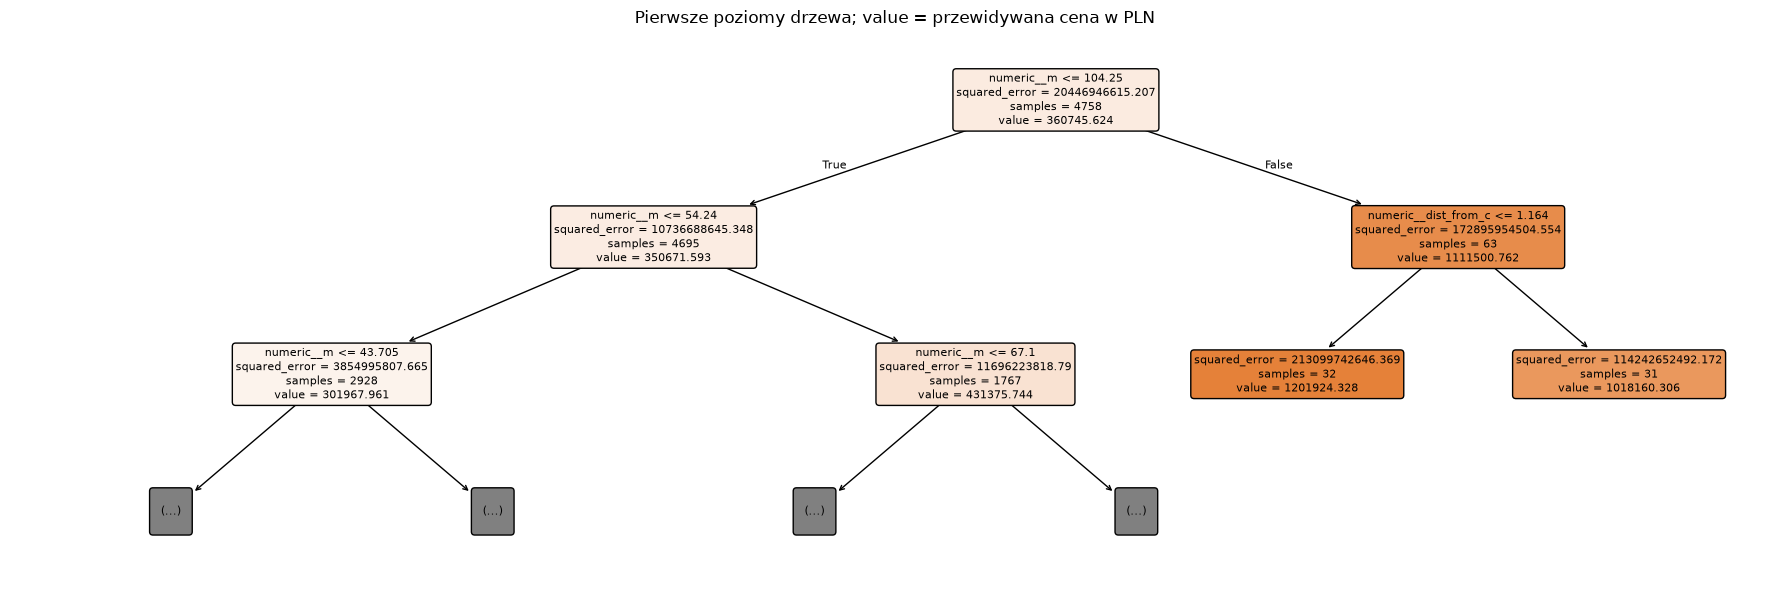

In [8]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

tree_preprocessing = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median', keep_empty_features=True), NUMERIC_VARS),
    ('rooms', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['no_rooms'])],
    sparse_threshold=0)
tree_model = evaluate('DecisionTree', Pipeline([
    ('preprocessing', tree_preprocessing),
    ('regression', DecisionTreeRegressor(max_depth=5, min_samples_leaf=30, random_state=42))]),
    df_train[room_features], df_test[room_features])
comparison = pd.DataFrame.from_dict(results, orient='index')
display(comparison.round(3))
assert comparison['n_test'].eq(len(test_idx)).all()

# Tylko transform: żadnego fit na teście.
tree_preprocessor = tree_model.named_steps['preprocessing']
tree_regressor = tree_model.named_steps['regression']
tree_names = tree_preprocessor.get_feature_names_out()
tree_train = pd.DataFrame(tree_preprocessor.transform(df_train[room_features]),
                          columns=tree_names, index=train_idx)
tree_test = pd.DataFrame(tree_preprocessor.transform(df_test[room_features]),
                         columns=tree_names, index=test_idx)
fig, ax = plt.subplots(figsize=(18, 6))
plot_tree(tree_regressor, feature_names=list(tree_names), max_depth=2,
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Pierwsze poziomy drzewa; value = przewidywana cena w PLN')
plt.tight_layout()
plt.show()

### SHAP — ważność na próbie testowej i pojedyncza predykcja

Dla TreeSHAP losujemy 100 ofert referencyjnych wyłącznie z treningu i do 200 ofert testowych do wyjaśnienia (stałe ziarno). Globalny ranking to średnia bezwzględna wartość SHAP w PLN na tej próbie, nie wpływ przyczynowy. Wkłady kategorii one-hot sumujemy w obrębie liczby pokoi **przed** obliczeniem wartości bezwzględnej.

Wykres waterfall wyjaśnia pierwszą chronologicznie ofertę testową: wartość bazowa + wkłady SHAP = predykcja. Zależność powierzchni i liczby pokoi oraz wybór danych referencyjnych wpływają na interpretację. [Dokumentacja TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).

Predykcja drzewa [PLN]: 328898.36


,mean_abs_SHAP_PLN
m,75141.87
no_rooms,7154.70
dist_from_c,5293.43


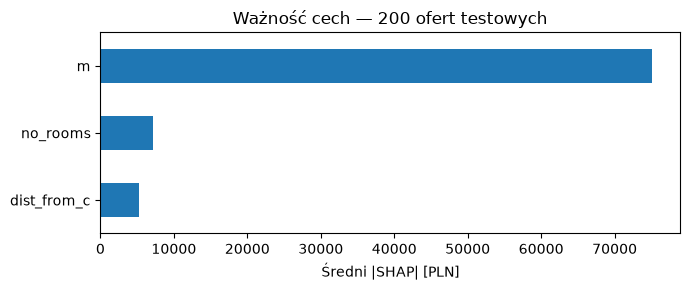

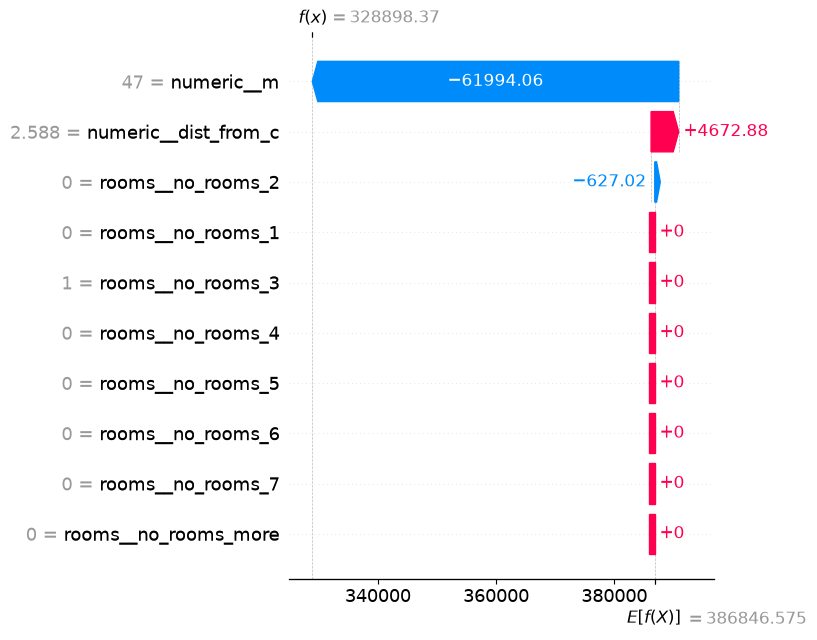

,id,m,dist_from_c,no_rooms,price
9809,8699554,47.0,2.588363,3,355000.0


In [9]:
import shap

background = tree_train.sample(n=min(100, len(tree_train)), random_state=42)
explain_idx = tree_test.sample(n=min(200, len(tree_test)), random_state=42).index
# Pierwsza oferta testowa jest zawsze w próbie, niezależnie od losowania.
example_idx = test_idx[0]
explain_idx = pd.Index([example_idx]).append(explain_idx.drop(example_idx, errors='ignore'))[:200]
X_explain = tree_test.loc[explain_idx]
shap_explainer = shap.TreeExplainer(tree_regressor, data=background,
                                   feature_perturbation='interventional')
shap_values = shap_explainer(X_explain)
np.testing.assert_allclose(shap_values.base_values + shap_values.values.sum(axis=1),
                           tree_regressor.predict(X_explain.to_numpy()), rtol=1e-5, atol=1)
shap_groups = {'m': [i for i, name in enumerate(tree_names) if name == 'numeric__m'],
               'dist_from_c': [i for i, name in enumerate(tree_names) if name == 'numeric__dist_from_c'],
               'no_rooms': [i for i, name in enumerate(tree_names) if name.startswith('rooms__')]}
group_shap = pd.DataFrame({name: shap_values.values[:, indices].sum(axis=1)
                          for name, indices in shap_groups.items()}, index=explain_idx)
shap_importance = group_shap.abs().mean().sort_values(ascending=False).to_frame('mean_abs_SHAP_PLN')
display(shap_importance.round(2))
shap_importance.sort_values('mean_abs_SHAP_PLN').plot.barh(legend=False, figsize=(7, 3))
plt.xlabel('Średni |SHAP| [PLN]')
plt.title(f'Ważność cech — {len(explain_idx)} ofert testowych')
plt.tight_layout()
plt.show()
shap.plots.waterfall(shap_values[0], max_display=10, show=False)
plt.tight_layout()
plt.show()
display(df_test.loc[[example_idx], ['id', 'm', 'dist_from_c', 'no_rooms', 'price']])
print('Predykcja drzewa [PLN]:', round(test_predictions.loc[example_idx, 'DecisionTree'], 2))

### LIME — lokalne przybliżenie tej samej predykcji

LIME dopasowuje lokalny model liniowy do predykcji drzewa na zaburzonych przykładach. Rozkłady, progi i kategorie wyznaczamy z treningu. Liczbę pokoi przekazujemy jako jedną cechę kategoryczną, aby nie losować sprzecznych kombinacji one-hot. Numeryczne braki uzupełniamy medianami z już dopasowanego pipeline.

Dodatnie wagi zwiększają lokalną predykcję, ujemne ją zmniejszają. Nie są to globalne ważności ani wartości SHAP. Lokalny R² mierzy zgodność przybliżenia LIME z drzewem na wygenerowanym sąsiedztwie, a nie jakość predykcji rzeczywistych cen. Sztuczne sąsiedztwo może zawierać mało realistyczne połączenia cech. [Dokumentacja LIME](https://lime-ml.readthedocs.io/en/latest/lime.html).

Lokalny R² LIME: 0.137
Predykcja drzewa [PLN]: 328898.36
Lokalne przybliżenie LIME [PLN]: 303481.49


,warunek,waga_PLN
0,41.30 < m <= 49.00,-257340.56
1,dist_from_c > 1.96,-22083.12
2,no_rooms=3,-4392.28


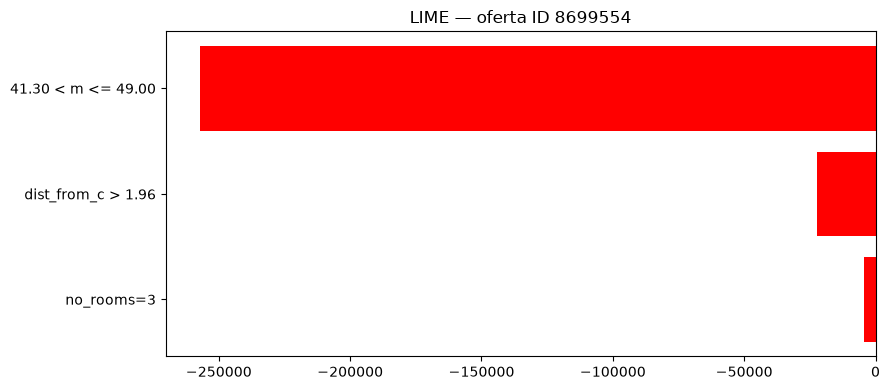

In [10]:
from lime.lime_tabular import LimeTabularExplainer

rooms_categories = list(tree_preprocessor.named_transformers_['rooms'].categories_[0])
rooms_codes = {value: i for i, value in enumerate(rooms_categories)}
# Gdyby w teście wystąpiła nowa kategoria, odpowiada wektorowi zer w OneHotEncoder.
unknown_code = len(rooms_categories)

def lime_input(frame):
    numeric = tree_preprocessor.named_transformers_['numeric'].transform(frame[NUMERIC_VARS])
    rooms = frame['no_rooms'].map(rooms_codes).fillna(unknown_code).to_numpy()
    return np.column_stack([numeric, rooms])

def lime_predict(array):
    frame = pd.DataFrame(array[:, :2], columns=NUMERIC_VARS)
    frame['no_rooms'] = [rooms_categories[int(round(v))] if 0 <= int(round(v)) < len(rooms_categories)
                         else '__unseen__' for v in array[:, 2]]
    return tree_model.predict(frame[room_features])

lime_train = lime_input(df_train)
lime_test = lime_input(df_test)
np.testing.assert_allclose(lime_predict(lime_test), test_predictions['DecisionTree'])
lime_explainer = LimeTabularExplainer(
    training_data=lime_train, mode='regression', feature_names=room_features,
    categorical_features=[2], categorical_names={2: rooms_categories + ['__unseen__']},
    discretize_continuous=True, random_state=42)
lime_explanation = lime_explainer.explain_instance(
    lime_test[0], lime_predict, num_features=len(room_features), num_samples=5000)
lime_weights = pd.DataFrame(lime_explanation.as_list(), columns=['warunek', 'waga_PLN'])
display(lime_weights.round(2))
print('Lokalny R² LIME:', round(lime_explanation.score, 3))
print('Predykcja drzewa [PLN]:', round(float(lime_predict(lime_test[:1])[0]), 2))
print('Lokalne przybliżenie LIME [PLN]:', round(float(lime_explanation.local_pred[0]), 2))
fig = lime_explanation.as_pyplot_figure()
fig.set_size_inches(9, 4)
plt.title(f'LIME — oferta ID {df_test.loc[example_idx, "id"]}')
plt.tight_layout()
plt.show()

### Jak czytać wyniki

Ranking SHAP opisuje przeciętną wielkość wkładu cechy na badanej próbie testowej. Waterfall SHAP i LIME dotyczą tej samej, wybranej z góry oferty. Rozbieżność między nimi jest możliwa: SHAP rozkłada predykcję względem tła treningowego, a LIME dopasowuje przybliżenie w sztucznym lokalnym sąsiedztwie. Przy niskim lokalnym R² nie interpretuj wag LIME jako wiernego opisu drzewa. Testowe wyjaśnienia służą końcowemu audytowi — jeśli na ich podstawie zmienisz model, potrzebny będzie nowy, niezależny test.


**Wynik tego uruchomienia:** drzewo ma MAE 50 242,88 PLN, RMSE 91 803,47 PLN i R² 0,580. Średni |SHAP| na 200 ofertach wynosi: powierzchnia 75 141,87 PLN, liczba pokoi 7 154,70 PLN, odległość 5 293,43 PLN. To wielkości wkładu do predykcji, a nie błędy ani stałe efekty zwiększenia cechy o jednostkę.

Dla pierwszej oferty testowej lokalny R² LIME to tylko 0,137. Nie interpretujemy więc jego dużych wag jako wiernego wyjaśnienia drzewa. W treningu jest skrajna powierzchnia 267 000 m², która może wpływać na sztuczne sąsiedztwo LIME i szerokość rozkładu ceny. Weryfikację tej wartości oraz dalsze eksperymenty należy prowadzić na treningu/walidacji.


## 9. Opcjonalny eksperyment z modelem językowym

Model odpowiadający na pytania nie bierze udziału w porównaniu regresji. Domyślnie pomijamy logowanie i pobieranie, aby notebook można było wykonać od początku do końca bez interakcji. Zmień flagę, jeśli chcesz uruchomić ten eksperyment.

In [11]:
RUN_QA = False
if RUN_QA:
    from transformers import AutoTokenizer, AutoModelForQuestionAnswering
    tokenizer = AutoTokenizer.from_pretrained('Aleksandra/herbert-base-cased-finetuned-squad')
    qa_model = AutoModelForQuestionAnswering.from_pretrained('Aleksandra/herbert-base-cased-finetuned-squad')

## 10. Prosta eksploracja danych (EDA)

Celem jest poznanie jakości danych i zależności przydatnych do przewidywania **ceny ofertowej**, a nie ceny transakcyjnej. Najpierw audyt całego pliku; rozkłady i zależności analizujemy wyłącznie na części treningowej rynku wtórnego. Nie usuwamy obserwacji tylko dlatego, że są nietypowe. Ta sekcja korzysta z kopii wspólnego `df_train`.


In [12]:
import matplotlib.pyplot as plt
from IPython.display import display

eda_raw = plik.copy()
quality = pd.DataFrame({
    'typ': eda_raw.dtypes.astype(str),
    'braki_n': eda_raw.isna().sum(),
    'braki_pct': eda_raw.isna().mean().mul(100),
    'unikalne': eda_raw.nunique(),
})
display(quality.round(2))
print('Wymiary:', eda_raw.shape)
print('Dokładnie powtórzone wiersze:', eda_raw.duplicated().sum())
print('Powtórzenia ID ponad pierwsze wystąpienie:', eda_raw['id'].duplicated().sum())
display(eda_raw['market'].value_counts(dropna=False).to_frame('liczba'))


Wymiary: (13745, 15)
Dokładnie powtórzone wiersze: 0
Powtórzenia ID ponad pierwsze wystąpienie: 1


,typ,braki_n,braki_pct,unikalne
id,int64,0,0.00,13744
market,str,0,0.00,2
created_at_first,str,0,0.00,13720
created_at,str,0,0.00,9851
district_lon,float64,187,1.36,31
district_lat,float64,187,1.36,31
title,str,927,6.74,8446
description,str,0,0.00,8456
params,str,0,0.00,10821
price,float64,0,0.00,3454


,liczba
market,
primary,7791
secondary,5954


### Ten sam trening co w modelach

Nie tworzymy nowego podziału. Korzystamy z `df_train`, `train_idx` i granicy `cutoff` z sekcji 2.

In [13]:
eda_train = df_train.copy()
assert eda_train.index.equals(train_idx)
print('Granica testu:', cutoff.date())
print('Trening:', len(eda_train), '| test:', len(df_test))
print('Zakres treningu:', eda_train['published_at'].min(), '—', eda_train['published_at'].max())

Granica testu: 2020-05-24
Trening: 4758 | test: 1196
Zakres treningu: 2018-01-02 11:34:51 — 2020-05-22 14:06:09


### Poprawność liczb i odporne statystyki

Wartości niefinitywne i niedodatnie ceny/powierzchnie wykluczamy jedynie z analiz wymagających dodatnich liczb. Reguła 1,5 IQR jest sygnałem do sprawdzenia, nie dowodem błędu. Mediana i kwartyle są mniej wrażliwe na skrajności niż średnia i odchylenie standardowe.


In [14]:
for col in ['price', 'm', 'price_per_m']:
    eda_train[col] = pd.to_numeric(eda_train[col], errors='coerce')
checks = pd.DataFrame({
    'brak_lub_niefinitywne': [int((~np.isfinite(eda_train[c])).sum()) for c in ['price', 'm']],
    'niedodatnie': [int(eda_train[c].le(0).sum()) for c in ['price', 'm']],
}, index=['price', 'm'])
display(checks)
valid = (np.isfinite(eda_train[['price', 'm']]).all(axis=1)
         & eda_train['price'].gt(0) & eda_train['m'].gt(0))
eda_valid = eda_train.loc[valid].copy()
print('Wykluczone z analiz ceny i powierzchni:', int((~valid).sum()))
display(eda_valid[['price', 'm', 'price_per_m']].describe(
    percentiles=[.01, .25, .5, .75, .99]).T.round(2))
q1, q3 = eda_valid[['price', 'm']].quantile(.25), eda_valid[['price', 'm']].quantile(.75)
iqr = q3 - q1
flags = ((eda_valid[['price', 'm']] < q1 - 1.5 * iqr)
         | (eda_valid[['price', 'm']] > q3 + 1.5 * iqr))
display(flags.sum().to_frame('poza_1.5_IQR'))
display(eda_valid.nlargest(5, 'm')[['id', 'm', 'price', 'price_per_m']])


Wykluczone z analiz ceny i powierzchni: 0


,brak_lub_niefinitywne,niedodatnie
price,0,0
m,0,0


,count,mean,std,min,1%,25%,50%,75%,99%,max
price,4758.0,360745.62,143007.85,19906.0,175000.00,285000.00,335000.00,396703.50,915442.51,2400000.0
m,4758.0,109.35,3870.05,15.2,25.00,41.30,49.00,63.00,110.73,267000.0
price_per_m,4758.0,6882.37,1438.64,1.0,4274.19,5908.31,6743.36,7779.44,10705.62,20000.0


,poza_1.5_IQR
price,297
m,90


,id,m,price,price_per_m
5130,7691341,267000.000000,267000.0,1.00
7248,8316787,193.589996,1407005.0,7267.96
3284,5965537,165.529999,1311260.0,7921.59
74,549536,160.000000,2190000.0,13687.50
1076,2402285,160.000000,1970000.0,12312.50


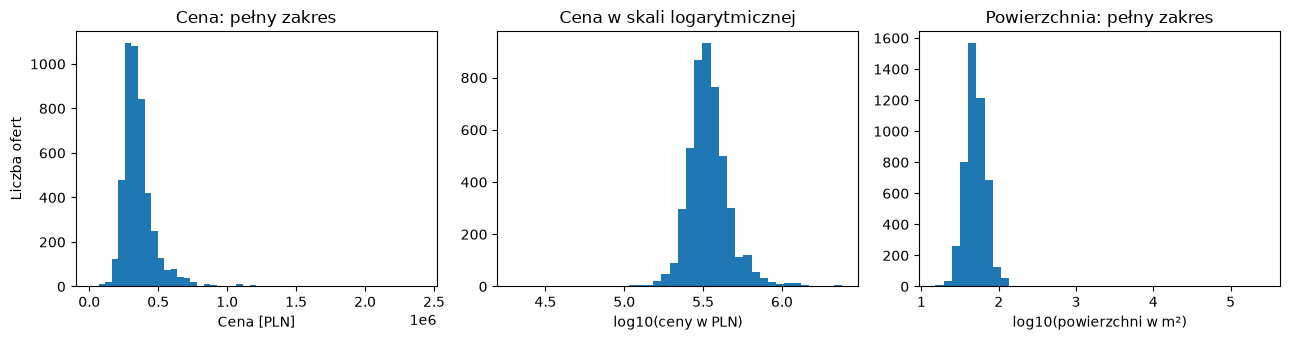

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(eda_valid['price'], bins=50)
axes[0].set(xlabel='Cena [PLN]', ylabel='Liczba ofert', title='Cena: pełny zakres')
axes[1].hist(np.log10(eda_valid['price']), bins=40)
axes[1].set(xlabel='log10(ceny w PLN)', title='Cena w skali logarytmicznej')
axes[2].hist(np.log10(eda_valid['m']), bins=40)
axes[2].set(xlabel='log10(powierzchni w m²)', title='Powierzchnia: pełny zakres')
fig.tight_layout()
plt.show()


### Zależności: powierzchnia i liczba pokoi

Współczynnik Pearsona opisuje zależność liniową i jest wrażliwy na skrajności. Spearman opisuje zależność monotoniczną na podstawie rang. Korelacja nie oznacza przyczynowości. Kategoria `more` pozostaje kategorią — nie przypisujemy jej arbitralnej liczby 8,5.


pearson
spearman


,price,m
price,1.000,-0.006
m,-0.006,1.000


,price,m
price,1.000,0.785
m,0.785,1.000


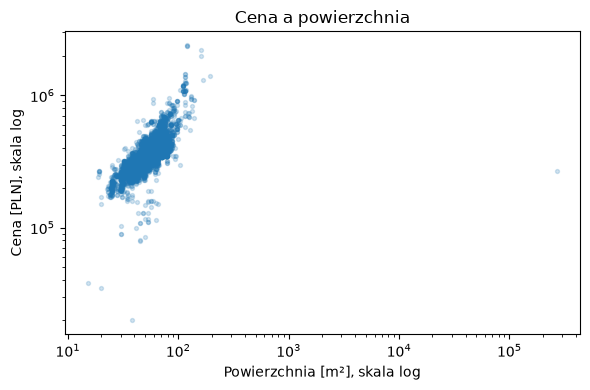

,n,mediana,q1,q3
no_rooms,,,,
1,459,240000.0,215000.0,269724.00
2,2057,299000.0,270000.0,349000.00
3,1855,369000.0,335000.0,425000.00
4,340,439500.5,389000.0,563750.00
5,34,564500.0,442250.0,695914.12
6,11,517000.0,488000.0,530500.00
7,1,400000.0,400000.0,400000.00
more,1,280000.0,280000.0,280000.00


In [16]:
for method in ['pearson', 'spearman']:
    print(method)
    display(eda_valid[['price', 'm']].corr(method=method).round(3))
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(eda_valid['m'], eda_valid['price'], s=8, alpha=.2)
ax.set(xscale='log', yscale='log', xlabel='Powierzchnia [m²], skala log',
       ylabel='Cena [PLN], skala log', title='Cena a powierzchnia')
fig.tight_layout()
plt.show()
rooms_summary = eda_valid.groupby('no_rooms', dropna=False)['price'].agg(
    n='size', mediana='median', q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75))
display(rooms_summary.round(2))


### Tekst i cena ukryta w cechach

`price_per_m` jest pochodną celu: w przybliżeniu `price / m`. Używanie go do przewidywania ceny prowadzi do wycieku informacji. Pole `params` zawiera również jawne pola ceny. Modele powyżej pomijają `price_per_m` i używają oczyszczonego `params_clean`; tutaj kontrolujemy surowe dane. Także tytuł i opis mogą zawierać cenę — trzeba sprawdzić przykłady i ustalić, czy taka informacja będzie dostępna w rzeczywistym zastosowaniu.


In [17]:
reconstructed = eda_valid['m'] * eda_valid['price_per_m']
relative_error = ((reconstructed - eda_valid['price']).abs() / eda_valid['price']).dropna()
print('Odsetek dostępnych rekordów z |m × price_per_m − price| / price < 1%:',
      f'{relative_error.lt(.01).mean():.1%}')
text_rows = []
for col in ['title', 'description', 'params']:
    text = eda_train[col].fillna('').astype(str)
    clean = text.str.replace(r'<[^>]*>', ' ', regex=True).str.strip()
    text_rows.append({'pole': col, 'puste_pct': clean.eq('').mean() * 100,
                      'mediana_znakow': clean.str.len().median(),
                      'p95_znakow': clean.str.len().quantile(.95)})
display(pd.DataFrame(text_rows).set_index('pole').round(1))
params_has_price = eda_train['params'].fillna('').str.contains(
    r'(?:^|<br\s*/?>)(?:price|price_per_m)<=>', regex=True)
print('Udział params z polem ceny:', f'{params_has_price.mean():.1%}')


Odsetek dostępnych rekordów z |m × price_per_m − price| / price < 1%: 100.0%
Udział params z polem ceny: 100.0%


,puste_pct,mediana_znakow,p95_znakow
pole,,,
title,14.8,40.0,50.0
description,0.0,1439.0,3083.4
params,0.0,464.0,570.0


### Liczebność i ceny w czasie

Miesięczne mediany opisują skład dostępnych ogłoszeń; nie są indeksem zmian cen tych samych mieszkań. Liczebność pomaga ocenić, czy mediana opiera się na małej próbie. Pierwszy i ostatni miesiąc mogą być niepełne.


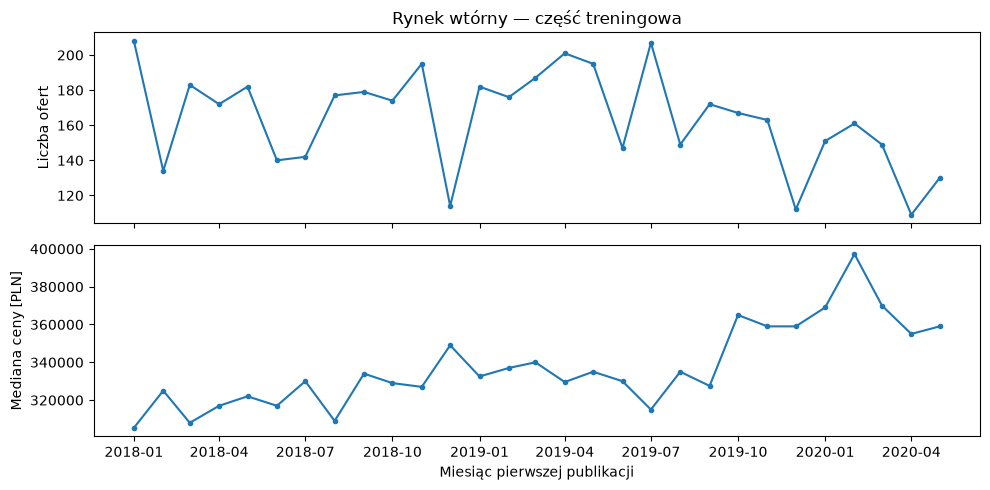

,size,median
published_at,,
2019-12-01,112,359000.0
2020-01-01,151,369000.0
2020-02-01,161,397232.0
2020-03-01,149,370000.0
2020-04-01,109,355000.0
2020-05-01,130,359000.0


In [18]:
monthly = eda_valid.set_index('published_at')['price'].resample('MS').agg(['size', 'median'])
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(monthly.index, monthly['size'], marker='.')
axes[0].set(ylabel='Liczba ofert', title='Rynek wtórny — część treningowa')
axes[1].plot(monthly.index, monthly['median'], marker='.')
axes[1].set(ylabel='Mediana ceny [PLN]', xlabel='Miesiąc pierwszej publikacji')
fig.tight_layout()
plt.show()
display(monthly.tail(6).round(2))


### Wnioski do dalszego modelowania

- Wszystkie modele i EDA korzystają z tego samego treningu; test ma identyczne ID i kolejność w każdym porównaniu.
- Imputacja, skalowanie, kodowanie kategorii i TF-IDF są dopasowywane tylko na treningu.
- Cena za m² i pola cenowe z `params` nie są cechami modeli. Tytuły i opisy nadal wymagają kontroli jawnej ceny.
- Zweryfikuj największe powierzchnie i ceny u źródła. Reguła 1,5 IQR nie jest automatycznym filtrem.
- Dalsze strojenie wymaga walidacji wewnątrz treningu, np. kolejnych okien czasowych. Nie dobieraj parametrów na podstawie testu.
- Porównaj modele z medianą treningową; rozważ logarytm ceny, nadal raportując błędy w PLN.